# Day 4 — Multimodal Retrieval

Load the Day 3 FAISS index and implement text-only and text-plus-image retrieval across text chunks, captions, and image vectors.

## 1. Install dependencies

Install FAISS and the libraries needed to load CLIP and display retrieved images.

In [1]:
!pip -q install faiss-cpu transformers torch pillow pandas

## 2. Imports

Import the retrieval, embedding, metadata, and image-handling libraries.

In [2]:
from pathlib import Path
import json
import numpy as np
import torch
import torch.nn.functional as F
import faiss
import pandas as pd
from PIL import Image
from transformers import CLIPProcessor, CLIPModel
from google.colab import files

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

Device: cpu


## 3. Upload Day 3 index files and image files

Upload multimodal_faiss.index and multimodal_metadata.json from Day 3. Upload the extracted image files too, so image results can be displayed.

In [3]:
uploaded = files.upload()

index_file = next((name for name in uploaded if name.endswith(".index")), None)
metadata_file = next((name for name in uploaded if name.endswith(".json") and "metadata" in name), None)

image_extensions = {".png", ".jpg", ".jpeg", ".webp", ".bmp"}
uploaded_images = [
    name for name in uploaded
    if Path(name).suffix.lower() in image_extensions
]

if not index_file or not metadata_file:
    raise ValueError("Upload multimodal_faiss.index and multimodal_metadata.json.")

print("Index:", index_file)
print("Metadata:", metadata_file)
print("Image files:", len(uploaded_images))

Saving multimodal_metadata.json to multimodal_metadata.json
Saving multimodal_faiss.index to multimodal_faiss.index
Index: multimodal_faiss.index
Metadata: multimodal_metadata.json
Image files: 0


## 4. Load FAISS index and metadata

Load the vector index and the metadata list; the list positions correspond to FAISS result positions.

In [4]:
index = faiss.read_index(index_file)

with open(metadata_file, "r", encoding="utf-8") as file:
    metadata = json.load(file)

if index.ntotal != len(metadata):
    raise ValueError(f"Index has {index.ntotal} vectors but metadata has {len(metadata)} records.")

image_lookup = {Path(name).name: name for name in uploaded_images}
for record in metadata:
    path = record.get("image_path")
    if path:
        record["image_path"] = image_lookup.get(Path(path).name, path)

print("Vectors in index:", index.ntotal)
print("Metadata records:", len(metadata))
print("Embedding dimension:", index.d)

Vectors in index: 42
Metadata records: 42
Embedding dimension: 512


## 5. Load CLIP

Load the same CLIP checkpoint used in Days 2 and 3 to ensure query vectors match the indexed vectors.

In [5]:
clip_model_id = "openai/clip-vit-base-patch32"
clip_processor = CLIPProcessor.from_pretrained(clip_model_id)
clip_model = CLIPModel.from_pretrained(clip_model_id).to(device)
clip_model.eval()

print("Loaded:", clip_model_id)

preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Loaded: openai/clip-vit-base-patch32


## 6. Define text and image embedding functions

Create normalized CLIP embeddings for text queries and uploaded query images.

In [6]:
@torch.inference_mode()
def embed_text_query(query):
    inputs = clip_processor(
        text=[query], return_tensors="pt",
        padding=True, truncation=True
    ).to(device)

    outputs = clip_model.text_model(
        input_ids=inputs["input_ids"],
        attention_mask=inputs["attention_mask"]
    )
    features = clip_model.text_projection(outputs.pooler_output)
    features = F.normalize(features, p=2, dim=-1)
    return features.cpu().numpy().astype("float32")


@torch.inference_mode()
def embed_image_query(image):
    if not isinstance(image, Image.Image):
        image = Image.open(image).convert("RGB")
    else:
        image = image.convert("RGB")

    inputs = clip_processor(images=image, return_tensors="pt").to(device)
    outputs = clip_model.vision_model(pixel_values=inputs["pixel_values"])
    features = clip_model.visual_projection(outputs.pooler_output)
    features = F.normalize(features, p=2, dim=-1)
    return features.cpu().numpy().astype("float32")

## 7. Define search function

Search the shared index and attach each result's modality, source document, page, text, image path, and similarity score.

In [7]:
def search_vectors(query_vector, top_k=5):
    query_vector = np.asarray(query_vector, dtype="float32").reshape(1, -1)
    faiss.normalize_L2(query_vector)

    scores, indices = index.search(query_vector, min(top_k, index.ntotal))
    results = []

    for score, idx in zip(scores[0], indices[0]):
        if idx < 0:
            continue
        record = metadata[int(idx)].copy()
        record["similarity"] = round(float(score), 4)
        results.append(record)

    return results


def display_results(results):
    if not results:
        print("No results found.")
        return

    display(pd.DataFrame([
        {
            "modality": r.get("modality"),
            "content_type": r.get("content_type"),
            "source_doc": r.get("source_doc"),
            "page": r.get("page"),
            "similarity": r.get("similarity"),
            "content": r.get("text")
        }
        for r in results
    ]))

    for result in results:
        path = result.get("image_path")
        if path and Path(path).exists():
            print("Retrieved image:", result.get("source_doc"),
                  "| page:", result.get("page"),
                  "| similarity:", result.get("similarity"))
            display(Image.open(path).convert("RGB"))

## 8. Text-only retrieval

Search all indexed spaces using a text query; results may be text chunks, image captions, or image vectors.

In [8]:
text_query = "What equipment was supplied to the customer?"
text_query_vector = embed_text_query(text_query)
text_results = search_vectors(text_query_vector, top_k=8)

print("Query:", text_query)
display_results(text_results)

Query: What equipment was supplied to the customer?


,modality,content_type,source_doc,page,similarity,content
0,text,text,sample_multimodal_invoice.pdf,1,0.9032,Items and Services
1,text,text,sample_multimodal_invoice.pdf,1,0.9009,Supplier
2,text,text,sample_multimodal_invoice.pdf,1,0.8890,Grand Total
3,text,text,sample_multimodal_invoice.pdf,2,0.8839,Service Summary
4,text,text,sample_multimodal_invoice.pdf,1,0.8820,Notes: Goods supplied are covered by the manuf...
5,text,text,sample_multimodal_invoice.pdf,1,0.8762,Original for recipient
6,text,text,sample_multimodal_invoice.pdf,1,0.8729,Authorised Signatory
7,text,text,sample_multimodal_invoice.pdf,2,0.8707,Service and Delivery Details


## 9. Text plus image retrieval

Upload an image and combine its CLIP vector with a text-query vector to search using both inputs.

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

model.safetensors: downloading bytes:           |  0.00B            

Saving module-6-day-4-query-image.png to module-6-day-4-query-image.png


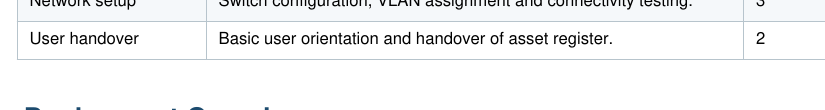

Query image: module-6-day-4-query-image.png


In [9]:
query_upload = files.upload()
query_image_files = [
    name for name in query_upload
    if Path(name).suffix.lower() in image_extensions
]
if not query_image_files:
    raise ValueError("Upload an image file for the text-plus-image query.")

query_image_path = query_image_files[0]
query_image = Image.open(query_image_path).convert("RGB")

display(query_image)
print("Query image:", query_image_path)

## 10. Combine text and image query vectors

Normalize both query vectors and combine them with equal weighting to create one multimodal query.

In [10]:
text_query = "Find document content related to this image."
text_vector = embed_text_query(text_query)
image_vector = embed_image_query(query_image)

combined_vector = 0.5 * text_vector + 0.5 * image_vector
combined_vector = combined_vector / np.linalg.norm(combined_vector, axis=1, keepdims=True)

print("Text vector shape:", text_vector.shape)
print("Image vector shape:", image_vector.shape)
print("Combined vector shape:", combined_vector.shape)

Text vector shape: (1, 512)
Image vector shape: (1, 512)
Combined vector shape: (1, 512)


## 11. Retrieve with the combined query

Search the same FAISS index using the combined text and image representation.

In [11]:
multimodal_results = search_vectors(combined_vector, top_k=8)
print("Text query:", text_query)
print("Image query:", query_image_path)
display_results(multimodal_results)

Text query: Find document content related to this image.
Image query: module-6-day-4-query-image.png


,modality,content_type,source_doc,page,similarity,content
0,text,text,sample_multimodal_invoice.pdf,2,0.7357,Document Control
1,text,text,sample_multimodal_invoice.pdf,1,0.7280,Notes: Goods supplied are covered by the manuf...
2,text,text,sample_multimodal_invoice.pdf,1,0.7192,Original for recipient
3,text,text,sample_multimodal_invoice.pdf,1,0.7146,Authorised Signatory
4,text,text,sample_multimodal_invoice.pdf,2,0.7117,Service Summary
5,text,text,sample_multimodal_invoice.pdf,1,0.7105,Grand Total
6,text,text,sample_multimodal_invoice.pdf,1,0.7101,Items and Services
7,text,text,sample_multimodal_invoice.pdf,1,0.7084,Bill To


## 12. Cross-modal retrieval: text query to image results

Filter the text-only results to check whether a text query retrieves image or caption records.

In [12]:
text_to_visual = [
    result for result in text_results
    if result.get("modality") in ["image", "caption"]
]

print("Visual results returned from text query:", len(text_to_visual))
display_results(text_to_visual)

Visual results returned from text query: 0
No results found.


## 13. Cross-modal retrieval: image query to text results

Search using only the uploaded image, then inspect whether the results include related text chunks.

In [13]:
image_only_vector = embed_image_query(query_image)
image_only_results = search_vectors(image_only_vector, top_k=8)

image_to_text = [
    result for result in image_only_results
    if result.get("modality") == "text"
]

print("Text results returned from image query:", len(image_to_text))
display_results(image_to_text)

Text results returned from image query: 2


,modality,content_type,source_doc,page,similarity,content
0,text,text,sample_multimodal_invoice.pdf,1,0.2585,Notes: Goods supplied are covered by the manuf...
1,text,text,sample_multimodal_invoice.pdf,2,0.2538,Document Control


## 14. Compare retrieval modes

Compare the top results from text-only, image-only, and combined text-plus-image retrieval.

In [14]:
def result_summary(results, mode):
    return [
        {
            "query_mode": mode,
            "rank": rank,
            "modality": item.get("modality"),
            "page": item.get("page"),
            "similarity": item.get("similarity"),
            "content": item.get("text")
        }
        for rank, item in enumerate(results, start=1)
    ]

comparison = (
    result_summary(text_results, "text-only")
    + result_summary(image_only_results, "image-only")
    + result_summary(multimodal_results, "text+image")
)

comparison_df = pd.DataFrame(comparison)
display(comparison_df)

,query_mode,rank,modality,page,similarity,content
0,text-only,1,text,1.0,0.9032,Items and Services
1,text-only,2,text,1.0,0.9009,Supplier
2,text-only,3,text,1.0,0.8890,Grand Total
3,text-only,4,text,2.0,0.8839,Service Summary
4,text-only,5,text,1.0,0.8820,Notes: Goods supplied are covered by the manuf...
5,text-only,6,text,1.0,0.8762,Original for recipient
6,text-only,7,text,1.0,0.8729,Authorised Signatory
7,text-only,8,text,2.0,0.8707,Service and Delivery Details
8,image-only,1,image,NaN,0.7591,the table shows the different types of product...
9,image-only,2,image,NaN,0.7154,table showing the different types of services


## 15. Save retrieval results

Save the retrieved records and scores so the retrieval behavior can be reviewed and used in Day 5.

In [15]:
output = {
    "text_query": text_query,
    "text_only_results": text_results,
    "image_only_results": image_only_results,
    "text_plus_image_results": multimodal_results,
    "comparison": comparison
}

output_path = Path("day4_retrieval_results.json")
with open(output_path, "w", encoding="utf-8") as file:
    json.dump(output, file, ensure_ascii=False, indent=2, default=str)

print("Saved:", output_path)

Saved: day4_retrieval_results.json


## 16. Download retrieval results

Download the retrieval output JSON for the grounded-generation step.

In [16]:
files.download(str(output_path))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Notebook summary

This notebook loads the Day 3 FAISS index and metadata, then implements text-only, image-only, and combined text-plus-image retrieval using CLIP. It searches across indexed text chunks, captions, and image vectors, preserves source and page metadata, displays available retrieved images, and compares the results from each query mode. The retrieval results are saved as JSON for the grounded-generation stage.